# 00 · Overview of the generator

This series of notebooks explains every part of `nxgen`, the modular synthetic brain MRI
generator of WP3, in its **double-tree** version: one augmented label map, **several ground
truths** (one per label level, e.g. all labels / nxb16 / SuperSynth), and an image painted from one
of the levels with its own intensity tree. Notebook **13** explains the label levels in detail. It reproduces the model of `generator_v2` (SynthSeg-style images whose
intensities come from a NextBrain label tree) with small modules that can be run, inspected
and tested one by one.

| Notebook | Topic |
|---|---|
| **00_overview** | the big picture: grids, the two phases (plan, render), one image end to end |
| 01_config_and_randomness | the config file, distribution specs, seeds and random streams |
| 02_labels_tree_label_space | the label tree, node visibility, generation classes, the label space |
| 03_offline_templates | building the HR templates (crop, sinc super-resolution, build record) |
| 04_acquisition | step 0: the simulated scan (resolution, slice thickness, contrast) |
| 05_morphology | step 1: growth/erosion between label groups |
| 06_spatial | step 2: affine + elastic deformation, source box, patch exactness |
| 07_partial_volume | step 3: partial volumes (downsample, smooth, sparse top-k) |
| 08_intensities_synthesis | step 4: Gaussians from the tree and the synthetic image |
| 09_artefacts_normalization | steps 5-6: bias, motion, resolution, noise, normalisation |
| 10_pipeline_plan_recorder | the Generator: plans, editing, recorder, patch mode, profiling |
| 11_training_cli_datasets | launchers, dataset layout, training stream, reproducibility |
| **13_label_levels_double_tree** | the label levels: MT, merging scripts, IT, one GT per level |
| 12_tests_and_checks | the test suite, the diagnostics, the benchmark |

Each notebook can be run on its own. They all start with `from _setup import *`, which only
sets paths, picks a device and defines small plotting helpers (see `notebooks/_setup.py`).

In [1]:
from _setup import *

print('package root :', ROOT)
print('device       :', DEVICE)
print('config       :', DT_CONFIG)
print('HR template  :', DT_TEMPLATE, '(nxbsimplified case-1, already at 0.2 mm)')

package root : /home/agustin/phd/synthseg_nextbrain/project/dev2/generator/generator_double_tree
device       : cuda:0
config       : /home/agustin/phd/synthseg_nextbrain/project/dev2/generator/generator_double_tree/configs/nxbsimplified_levels.json
HR template  : /home/agustin/phd/synthseg_nextbrain/project/dev2/simplified_trees_and_labels/data/outputs/nxbsimplified/labels/case-1.nii.gz (nxbsimplified case-1, already at 0.2 mm)


## 1. What the generator does

Input: label maps of real brains (here the simplified NextBrain `case-1`, 231 labels at 0.2 mm).
Output: an endless supply of (synthetic image, segmentations) tuples, all different, for
training a segmentation network that should work on any MRI contrast and resolution.

Every image is made by:

1. taking a label map and **changing its shape** a little (morphology + deformation), with the
   **morphological tree MT** (the fine labels);
2. **merging** the deformed labels into every **label level** of the config (e.g. all labels,
   16 classes, SuperSynth classes) with the merging scripts, and taking the partial volume of
   each: **one ground truth per level**;
3. giving every label of the **principal level** a **random intensity** (a Gaussian drawn from
   the **intensity tree IT**, the tree of that level);
4. simulating a **random scanner** (bias field, motion, resolution, noise).

```
L ─► HR template ─► morphology (MT) ─► spatial ─┬─► merge nxb_all ──► PV ─► GT nxb_all
                                                ├─► merge supersynth ► PV ─► GT nxbsupersynth
                                                └─► merge nxb16 ─────► PV ─► GT nxb16
                                                                       └─► synthesis (IT) ─► artefacts ─► image
```

The segmentations that go with the image are the merged deformed label maps, never degraded.

## 2. The package

```
nxgen/
├── core/          config, rng, io, tree, label_space, merging, geometry, bspline, recorder
├── offline/       template.py: label map -> HR template (run once)
├── online/        one file per step (acquisition ... normalization)
├── pipeline.py    Generator: sample_plan + render
├── training.py    SyntheticStream for a torch DataLoader
├── checks.py      diagnostics (used by the tests, never by the generator)
└── cli/           build_templates.py, generate.py
```

Every online module has the same two functions:

* `sample(config_section, rng, ...)` draws its random parameters and returns a plain dict
  (or `None` when the module is not applied). It never touches voxels.
* `apply(volume, params, ...)` does the work. It has no randomness.

## 3. Three grids

| Grid | Voxel | Used for |
|---|---|---|
| input | 0.2 mm here | the label maps given to the offline step |
| **HR** (template) | `template.hr_voxel_mm` = 0.2 mm | shape changes (morphology, deformation) |
| **output** | `grid.target_voxel_mm` = 0.4 mm | images and segmentations |

`factor = 0.4 / 0.2 = 2`: one output voxel covers 2×2×2 HR voxels. Working on a finer grid
lets boundaries fall *inside* output voxels, which is where partial volumes come from.

## 4. One image, end to end

The `Generator` loads the templates once (on the GPU, as int16 label indices), reads the merging
rule of every level (a small lookup table per level) and then makes images. `gen(seed)` is all you
need for one sample.

In [2]:
from nxgen import Generator, Recorder

gen = Generator([DT_TEMPLATE], DT_CONFIG, device=DEVICE)
print('fine labels (MT)          :', len(gen.labels))
print('label levels              :', {n: len(lv.labels) for n, lv in gen.levels.items()},
      '| principal:', gen.principal)
print('HR voxel / output voxel   :', gen.hr_voxel_mm, '/', gen.voxel_mm, 'mm  -> factor', gen.factor)
print('output grid of case-1     :', gen.templates[0]['out_shape'])

sample = gen(seed=0)
print('image', tuple(sample.image.shape), sample.image.dtype, 'range',
      float(sample.image.min()), float(sample.image.max()))
for name, seg in sample.segs.items():
    print(f'seg {name:14s}', tuple(seg.shape), seg.dtype, '->', len(torch.unique(seg)), 'labels present')

/home/agustin/phd/synthseg_nextbrain/project/dev2/libraries/trees/tree.py:387: UserWarning: gray_matter_of_forebrain_l1: r_max on level-1 nodes is ignored (always visible). Group structures that merge at coarse resolution under a common parent.
  warnings.warn(w)
/home/agustin/phd/synthseg_nextbrain/project/dev2/libraries/trees/tree.py:387: UserWarning: white_matter_of_forebrain_l1: r_max on level-1 nodes is ignored (always visible). Group structures that merge at coarse resolution under a common parent.
  warnings.warn(w)
/home/agustin/phd/synthseg_nextbrain/project/dev2/libraries/trees/tree.py:387: UserWarning: surface_structures_of_forebrain_l1: r_max on level-1 nodes is ignored (always visible). Group structures that merge at coarse resolution under a common parent.
  warnings.warn(w)
/home/agustin/phd/synthseg_nextbrain/project/dev2/libraries/trees/tree.py:387: UserWarning: gray_matter_of_midbrain_l1: r_max on level-1 nodes is ignored (always visible). Group structures that merge 

fine labels (MT)          : 231
label levels              : {'nxb_all': 231, 'nxbsupersynth': 19, 'nxb16': 17} | principal: nxb16
HR voxel / output voxel   : 0.2 / 0.4 mm  -> factor 2
output grid of case-1     : [224, 433, 294]


image (224, 433, 294) torch.float32 range 0.0 1.0
seg nxb_all        (224, 433, 294) torch.int16 -> 229 labels present
seg nxbsupersynth  (224, 433, 294) torch.int16 -> 19 labels present
seg nxb16          (224, 433, 294) torch.int16 -> 17 labels present


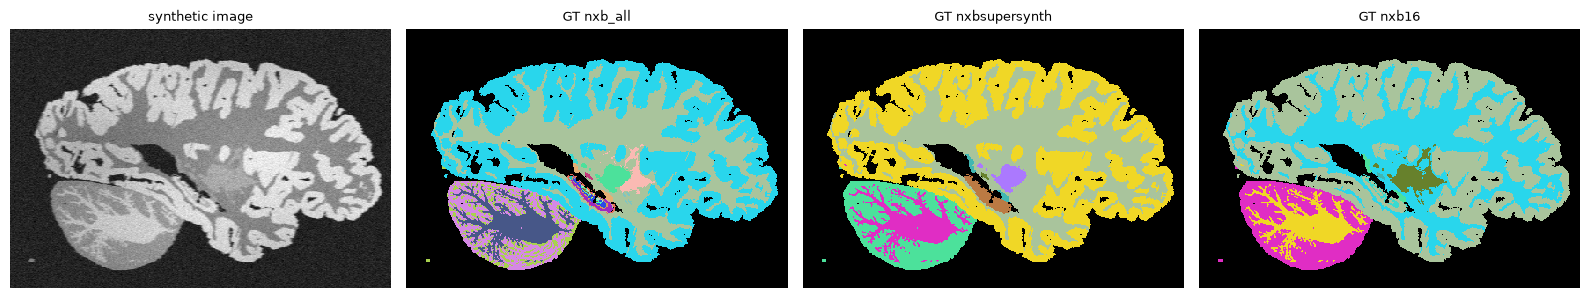

In [3]:
show([sample.image] + list(sample.segs.values()),
     ['synthetic image'] + [f'GT {n}' for n in sample.segs], axis=0, size=4)

## 5. Two phases: plan, then render

`gen(seed)` is a shortcut for `gen.render(gen.sample_plan(seed))`.

* **`sample_plan(seed)`** draws *every* random number of the image into a JSON-serialisable
  dict, the **plan**. It takes milliseconds and touches no voxel.
* **`render(plan)`** turns the plan into the image. Same plan → same result.

The plan is therefore the complete description of an image: you can save it, read it, edit it
and render it again.

In [4]:
import json
plan = gen.sample_plan(0)
print('plan keys:', list(plan))
print()
print('version    :', plan['version'])
print('roi        :', plan['roi'])
print('acquisition:', json.dumps(plan['acquisition']))
print('spatial    :', {k: v for k, v in plan['spatial'].items() if k != 'elastic_ctrl_mm'})
print('tree       :', {k: (v if not isinstance(v, list) or len(v) < 6 else f'[{len(v)} values]')
                       for k, v in plan['tree'].items()})
print('motion     :', plan['motion'])

plan keys: ['version', 'seed', 'config_hash', 'template', 'template_path', 'roi', 'acquisition', 'morphology', 'spatial', 'tree', 'bias', 'motion', 'noise']

version    : 2
roi        : {'start': [0, 0, 0], 'size': [224, 433, 294]}
acquisition: {"spacing_mm": [0.4, 0.49434413196560995, 0.4], "thickness_mm": [0.4, 0.4608175869788456, 0.4], "alpha": [1.0, 0.9894199019997904, 1.0], "contrast": "FLAIR"}
spatial    : {'rotation_deg': [2.4416537599499923, -4.953277729599478, -2.171116637278099], 'zoom': [0.9820450659464716, 1.0013530984407408, 1.0065808670956713], 'shear': [0.0, 0.0, 0.0], 'translation_mm': [0.0, 0.0, 0.0], 'matrix': [[0.9776752213845824, 0.037793655089235545, -0.08691157364224034], [-0.040779844802301166, 0.9995862737506023, -0.0427222114615998], [0.08307031538592866, 0.04590151109989735, 1.0019112899942455]], 'elastic_dmax_mm': 7.5}
tree       : {'colors_mu': '[7 values]', 'colors_sigma': '[7 values]', 'resolution_mm': 0.49434413196560995, 'contrast': 'FLAIR', 'mu': '[17 v

In [5]:
# in the plain keys what does it mean version and config_hash
# - Version is the version of the generator in case in the future we chnage something
# - Config_hash is a hash of the configuration, used with CLI when generating a dataset

# in the tree what is 'class_of': '[300 values]', 'class_names': '[263 values]', why do they differ?

Editing the plan changes only what you edit. Any augmentation section (`morphology`, `spatial`,
`acquisition`, `bias`, `motion`, `noise`) can be set to `None` to skip that step; only `tree`
(the intensities) is required. Here the same image without motion, without noise and with a
fixed thick-slice acquisition:

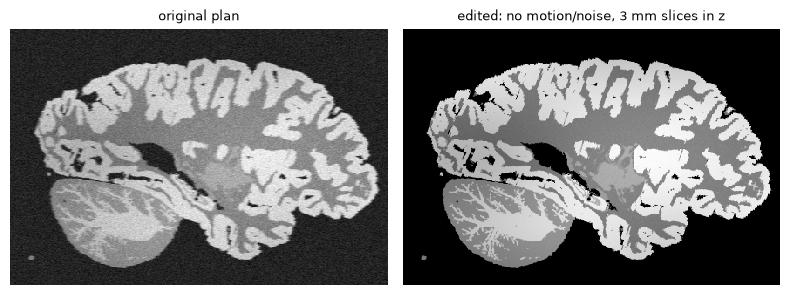

In [6]:
from nxgen.online import acquisition

edited = json.loads(json.dumps(plan))                   # deep copy
edited['motion'] = None
edited['noise'] = None
edited['acquisition'] = dict(plan['acquisition'], spacing_mm=[0.4,0.4,0.4],
                             thickness_mm=[1,1,1], alpha=[1, 1, 1])
show([gen.render(plan).image, gen.render(edited).image],
     ['original plan', 'edited: no motion/noise, 3 mm slices in z'], axis=0, size=4)

In [7]:
### if I manually change the mode to iso but I left the coordinetes as in the aniso case, the output is still anisotropic. Should it give an error instead?
### Same for the axis


**Answer (solved in plan version 2).** In version 1, `mode`, `axis` and `sigma_vox` were stored next
to the physical values, but the renderer only read `sigma_vox` and `spacing_mm` (and `mode` only to
skip the step when `'none'`). So an edited `mode`/`axis` was silently ignored, and an edited
`thickness_mm`/`alpha` too.

Now `plan['acquisition']` stores only `spacing_mm`, `thickness_mm`, `alpha` and `contrast`, the
single source of truth. Everything else is derived from them:

* an axis is degraded when its spacing is larger than the output voxel (`acquisition.degraded_axes`);
  on the other axes thickness and alpha are ignored;
* the slice-profile std is computed at render time (`acquisition.sigma_vox`, eq. 23);
* the mode is `acquisition.describe(acq, voxel_mm)` → `'none'`, `'iso'`, `'aniso'` or `'custom'`
  (a combination `sample` never draws, e.g. two thick axes; it still renders).

To remove the degradation: `plan['acquisition'] = None` (no need to know the voxel size).

## 6. All the steps of one image

A `Recorder` keeps the intermediate result of every step. The table below lists the steps in
order; the following notebooks explain each one.

| # | Step | Grid | Module |
|---|---|---|---|
| 0 | acquisition (drawn first, used by 4 and 5c) | – | `online/acquisition.py` |
| 1 | morphology | HR | `online/morphology.py` |
| 2 | spatial deformation | HR | `online/spatial.py` |
| 3a | merge into every label level | HR | `core/merging.py` |
| 3b | partial volume → one segmentation per level | HR → output | `online/partial_volume.py` |
| 4 | tree intensities (IT, principal level) + synthesis | output | `online/tree_intensities.py`, `synthesis.py` |
| 5a | bias field | output | `online/bias.py` |
| 5b | motion | output | `online/motion.py` |
| 5c | resolution (+ noise on the low-res grid) | output → low-res → output | `online/resolution.py` |
| 5d | noise | low-res or output | `online/noise.py` |
| 6 | normalisation | output | `online/normalization.py` |

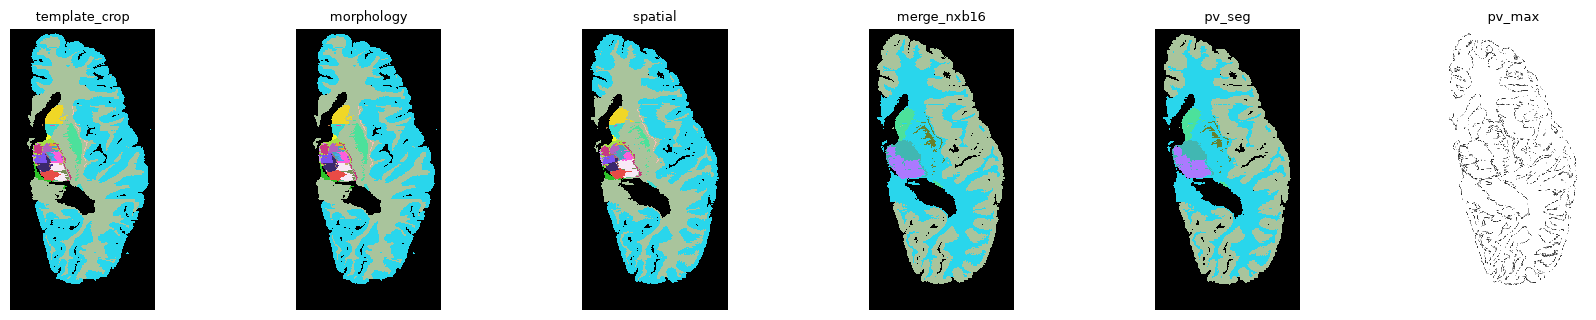

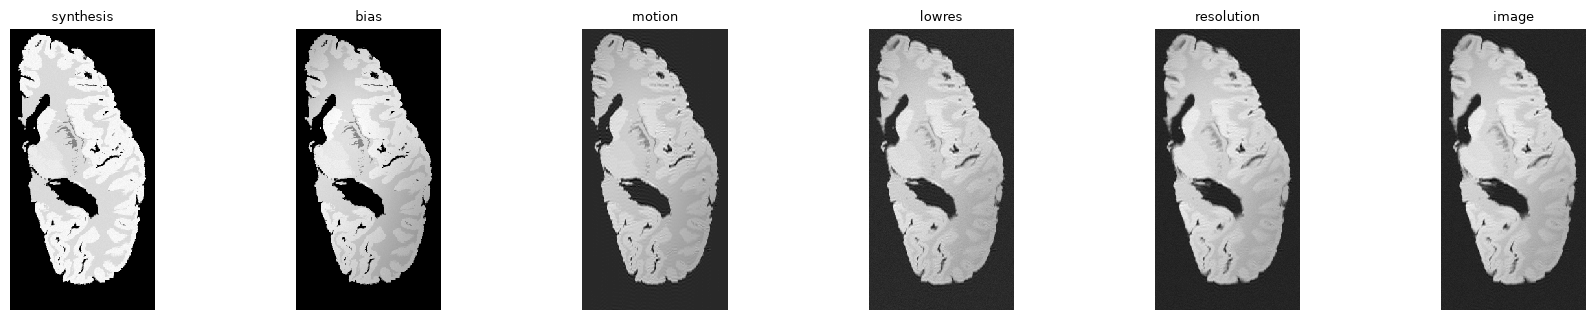

acquisition of this image: ('aniso', [2]) [0.4, 0.4, 0.9997816990517786]


In [8]:
from nxgen.core.config import load_config

worst = Generator([DT_TEMPLATE], load_config(DT_CONFIG, motion={'prob': 1.0},
                                             acquisition={'lowres_prob': 1.0}), device=DEVICE)
rec = Recorder(steps='all')
s = worst(1, recorder=rec)
names = ['template_crop', 'morphology', 'spatial', 'merge_nxb16', 'pv_seg', 'pv_max', 'synthesis',
         'bias', 'motion', 'lowres', 'resolution', 'image']
show([rec.steps[n] for n in names[:6]], names[:6], size=3)
show([rec.steps[n] for n in names[6:]], names[6:], size=3)
print('acquisition of this image:', acquisition.describe(s.plan['acquisition'], worst.voxel_mm),
      s.plan['acquisition']['spacing_mm'])
del worst

## 7. Patches for training

Networks are trained on patches. With `patch.size` set, only the part of the template a patch
needs is processed, which makes generation several times faster (notebook 10).

In [9]:
import time
pgen = Generator([DT_TEMPLATE], load_config(DT_CONFIG, patch={'size': [160, 160, 160]}), device=DEVICE)
pgen(0)                                                  # warm-up
print('benchmarking full volume vs 160^3 patch generation...')
for name, g in [('full volume', gen), ('160^3 patch', pgen)]:
    torch.cuda.synchronize(DEVICE) if DEVICE.startswith('cuda') else None
    t0 = time.perf_counter()
    for seed in range(5):
        out = g(seed)
    torch.cuda.synchronize(DEVICE) if DEVICE.startswith('cuda') else None
    print(f'{name:12s}: {(time.perf_counter() - t0) / 5:.3f} s per sample, shape {tuple(out.seg.shape)}')

benchmarking full volume vs 160^3 patch generation...


full volume : 0.518 s per sample, shape (224, 433, 294)


160^3 patch : 0.097 s per sample, shape (160, 160, 160)


## 8. Where to go next

* To understand **how parameters are set and drawn**: notebook 01.
* To understand **the intensity model**: notebooks 02 and 08.
* To understand **the label levels, MT and IT**: notebook 13.
* To **debug one image**: notebook 10 (plans + recorder).
* To **generate datasets or train**: notebook 11.
* Reference documentation: `README.md` and `docs/` in the package root.